In [24]:
# # CELL 0
# !pip -q install fastapi uvicorn requests pandas numpy matplotlib scipy psutil aiohttp

In [25]:
# CELL 1
from pathlib import Path

for d in ["region_service", "carl_router", "analysis", "analysis/plots",
          "data", "logs", "runs"]:
    Path(d).mkdir(parents=True, exist_ok=True)

print("Folders ready.")

Folders ready.


In [26]:
# CELL 2
from pathlib import Path

region_app = r'''
import os, time, random, asyncio
from fastapi import FastAPI, Request
import uvicorn

REGION = os.getenv("REGION", "R1")
BASE_DELAY_MS = float(os.getenv("BASE_DELAY_MS", "25"))
MAX_INFLIGHT = int(os.getenv("MAX_INFLIGHT", "50"))
CARBON_INTENSITY = float(os.getenv("CARBON_INTENSITY", "400"))   # gCO2/kWh (static illustrative value, see Cell 5)

# ---- power / carbon model: idle + dynamic power, PUE-adjusted (reviewer 5f) ----
P_IDLE_W = float(os.getenv("P_IDLE_W", "50"))
P_MAX_W  = float(os.getenv("P_MAX_W", "300"))
PUE      = float(os.getenv("PUE", "1.5"))

# ---- cold-start model (reviewer 6d) ----
KEEP_ALIVE_S = float(os.getenv("KEEP_ALIVE_S", "60"))
COLD_START_MS_MIN = float(os.getenv("COLD_START_MS_MIN", "300"))
COLD_START_MS_MAX = float(os.getenv("COLD_START_MS_MAX", "900"))

app = FastAPI()
INFLIGHT = 0
LAST_INVOKE_TS = 0.0

@app.get("/health")
async def health():
    return {"ok": True, "region": REGION}

@app.get("/load")
async def load():
    return {"region": REGION, "inflight": INFLIGHT, "load_score": min(1.0, INFLIGHT / float(MAX_INFLIGHT))}

@app.post("/invoke")
async def invoke(request: Request):
    global INFLIGHT, LAST_INVOKE_TS
    INFLIGHT += 1
    t0 = time.perf_counter()
    now = time.time()

    is_cold = (LAST_INVOKE_TS == 0.0) or ((now - LAST_INVOKE_TS) > KEEP_ALIVE_S)
    LAST_INVOKE_TS = now
    cold_penalty_ms = random.uniform(COLD_START_MS_MIN, COLD_START_MS_MAX) if is_cold else 0.0

    pressure = (INFLIGHT / float(MAX_INFLIGHT))
    delay_ms = BASE_DELAY_MS + (pressure * BASE_DELAY_MS * 4.0) + random.uniform(0, 8) + cold_penalty_ms
    fail_prob = max(0.0, pressure - 0.75) * 0.6

    await asyncio.sleep(delay_ms / 1000.0)

    status = 200
    if random.random() < fail_prob:
        status = 500

    t1 = time.perf_counter()
    exec_ms = (t1 - t0) * 1000.0
    INFLIGHT -= 1

    # carbon estimate for this single request: E(kWh) * PUE * grid intensity(gCO2/kWh)
    exec_hours = (exec_ms / 1000.0) / 3600.0
    power_w = P_IDLE_W + (P_MAX_W - P_IDLE_W) * pressure
    energy_kwh = (power_w * exec_hours) / 1000.0
    carbon_g = energy_kwh * PUE * CARBON_INTENSITY

    return {"region": REGION, "status": status, "exec_ms": exec_ms,
            "cold_start": is_cold, "carbon_g": carbon_g}

if __name__ == "__main__":
    port = int(os.getenv("PORT", "9001"))
    uvicorn.run(app, host="0.0.0.0", port=port, log_level="warning")
'''

Path("region_service/app.py").write_text(region_app)
print("Wrote region_service/app.py")

Wrote region_service/app.py


In [27]:
# CELL 3
from pathlib import Path

router_app = r'''
import os, time, csv, math, json, threading, asyncio
from pathlib import Path
from collections import deque
from typing import Dict, Any
import requests
import aiohttp
from fastapi import FastAPI, Request
import uvicorn

REQ_HEADER = [
    "run_id","scenario","pattern","mode","rep","timestamp","request_id","chosen_region",
    "status_code","e2e_latency_ms","function_exec_ms","cold_start",
    "region_latency_ms","region_load_score","region_carbon_intensity","carbon_g",
    "burst_factor","switch_flag"
]

REGIONS = json.loads(os.getenv("REGIONS_JSON", "{}"))          # {region_id: base_url}
CARBON_MAP = {k: float(v) for k, v in json.loads(os.getenv("CARBON_JSON", "{}")).items()}

SLA_MS = float(os.getenv("SLA_MS", "120.0"))
REQUESTS_LOG = Path(os.getenv("REQUESTS_LOG", "logs/requests.csv"))

W_LAT = float(os.getenv("W_LAT", "0.4"))
W_LOAD = float(os.getenv("W_LOAD", "0.3"))
W_CARB = float(os.getenv("W_CARB", "0.3"))
assert abs((W_LAT + W_LOAD + W_CARB) - 1.0) < 1e-6, "weights must sum to 1.0"

BETA_BURST = float(os.getenv("BETA_BURST", "0.8"))
LOAD_HISTORY_LEN = int(os.getenv("LOAD_HISTORY_LEN", "5"))

def now_s():
    return time.time()

class CsvLogger:
    def __init__(self, req_path: str):
        self.requests_path = Path(req_path)
        self.requests_path.parent.mkdir(parents=True, exist_ok=True)
        self._ensure_header()

    def _ensure_header(self):
        if not self.requests_path.exists() or self.requests_path.stat().st_size == 0:
            with self.requests_path.open("w", newline="", encoding="utf-8") as f:
                csv.writer(f).writerow(REQ_HEADER)

    def log_request(self, row: Dict[str, Any]) -> None:
        self._ensure_header()
        with self.requests_path.open("a", newline="", encoding="utf-8") as f:
            csv.DictWriter(f, fieldnames=REQ_HEADER).writerow(row)

logger = CsvLogger(str(REQUESTS_LOG))

class State:
    def __init__(self):
        self.latency = {k: None for k in REGIONS}
        self.load = {k: None for k in REGIONS}
        self.load_hist = {k: deque(maxlen=LOAD_HISTORY_LEN) for k in REGIONS}
        self.lock = threading.Lock()

    def set_latency(self, r, v):
        with self.lock:
            self.latency[r] = v

    def set_load(self, r, v):
        with self.lock:
            self.load[r] = v
            if v is not None:
                self.load_hist[r].append(v)

    def snapshot(self):
        with self.lock:
            return {"latency": self.latency.copy(), "load": self.load.copy(),
                     "load_hist": {k: list(v) for k, v in self.load_hist.items()}}

state = State()

# NOTE: these two polling helpers stay on the synchronous `requests` library
# on purpose -- they run once per second inside a dedicated background THREAD
# (poll_loop below), not inside the asyncio event loop, so they cannot block
# request handling. Only the per-request /route -> /invoke call (hot path,
# called hundreds of times per second under load) had to move to async I/O.
def ping_latency(base_url: str):
    try:
        t0 = time.perf_counter()
        r = requests.get(f"{base_url}/health", timeout=1.0)
        t1 = time.perf_counter()
        if r.status_code == 200:
            return (t1 - t0) * 1000.0
    except Exception:
        pass
    return None

def read_load(base_url: str):
    try:
        r = requests.get(f"{base_url}/load", timeout=1.0)
        if r.status_code == 200:
            return float(r.json().get("load_score", 0.0))
    except Exception:
        pass
    return None

def normalize(vals: Dict[str, float]):
    xs = [v for v in vals.values() if v is not None and not math.isnan(v)]
    if not xs:
        return {r: None for r in vals}
    mn, mx = min(xs), max(xs)
    if abs(mx - mn) < 1e-9:
        return {r: (0.0 if vals[r] is not None else None) for r in vals}
    return {r: (None if vals[r] is None else (vals[r] - mn) / (mx - mn)) for r in vals}

def choose_round_robin(counter=[0]):
    regs = list(REGIONS.keys())
    i = counter[0] % len(regs)
    counter[0] += 1
    return regs[i]

def choose_latency(snap):
    items = [(r, v) for r, v in snap["latency"].items() if v is not None]
    return min(items, key=lambda x: x[1])[0] if items else choose_round_robin()

def choose_load(snap):
    items = [(r, v) for r, v in snap["load"].items() if v is not None]
    return min(items, key=lambda x: x[1])[0] if items else choose_round_robin()

def choose_carbon_greedy(snap):
    healthy = [r for r in REGIONS if snap["latency"].get(r) is not None]
    pool = healthy if healthy else list(REGIONS.keys())
    return min(pool, key=lambda r: CARBON_MAP.get(r, 1e18))

def burst_factor(snap, r):
    hist = snap["load_hist"].get(r, [])
    if len(hist) < 2:
        return 1.0
    slope = hist[-1] - hist[0]
    return 1.0 + BETA_BURST * max(0.0, slope)

def choose_carl(snap, pattern="continuous"):
    lat_n = normalize(snap["latency"])
    load_n = normalize(snap["load"])
    carb_n = normalize(CARBON_MAP)

    best, best_score, best_bf = None, 1e18, 1.0
    for r in REGIONS:
        if snap["latency"].get(r) is not None and snap["latency"][r] > SLA_MS:
            continue
        if lat_n[r] is None or load_n[r] is None:
            continue

        if pattern == "bursty":
            bf = burst_factor(snap, r)
            score = (W_LAT * lat_n[r]) + (W_LOAD * load_n[r] * bf) + (W_CARB * carb_n[r])
        else:
            bf = 1.0
            score = (W_LAT * lat_n[r]) + (W_LOAD * load_n[r]) + (W_CARB * carb_n[r])

        if score < best_score:
            best_score, best, best_bf = score, r, bf

    if best is None:
        return choose_round_robin(), 1.0
    return best, best_bf

def poll_loop():
    while True:
        for r, url in REGIONS.items():
            state.set_latency(r, ping_latency(url))
            state.set_load(r, read_load(url))
        time.sleep(1.0)

threading.Thread(target=poll_loop, daemon=True).start()

app = FastAPI()
http_session: aiohttp.ClientSession = None

@app.on_event("startup")
async def startup_event():
    # Shared async client session for outgoing /invoke calls -- this is the fix.
    # A plain `requests.post` here would block the whole asyncio event loop and
    # serialize every concurrent request, which is what caused the near-total
    # request failures under load.
    global http_session
    connector = aiohttp.TCPConnector(limit=0)  # no artificial concurrency cap
    http_session = aiohttp.ClientSession(connector=connector)

@app.on_event("shutdown")
async def shutdown_event():
    await http_session.close()

@app.get("/health")
async def health():
    return {"ok": True, "service": "carl_router", "regions": list(REGIONS.keys())}

@app.post("/route")
async def route(req: Request):
    payload = await req.json()
    mode = payload.get("mode", "carl")
    pattern = payload.get("pattern", "continuous")
    request_id = payload.get("request_id", "0")
    scenario = payload.get("scenario", "scenario")
    run_id = payload.get("run_id", "run")
    rep = payload.get("rep", 0)

    snap = state.snapshot()
    burst_f = 1.0
    if mode == "round_robin":
        chosen = choose_round_robin()
    elif mode == "latency":
        chosen = choose_latency(snap)
    elif mode == "load":
        chosen = choose_load(snap)
    elif mode == "carbon_greedy":
        chosen = choose_carbon_greedy(snap)
    else:
        chosen, burst_f = choose_carl(snap, pattern=pattern)

    url = REGIONS[chosen]
    t0 = time.perf_counter()
    status_code, exec_ms, cold_start, carbon_g = 500, None, None, None
    try:
        async with http_session.post(f"{url}/invoke", json={"request_id": request_id},
                                      timeout=aiohttp.ClientTimeout(total=3.0)) as r:
            js = await r.json()
            status_code = int(js.get("status", r.status))
            exec_ms = float(js.get("exec_ms", 0.0))
            cold_start = bool(js.get("cold_start", False))
            carbon_g = float(js.get("carbon_g", 0.0))
    except Exception:
        status_code = 500

    t1 = time.perf_counter()
    e2e_ms = (t1 - t0) * 1000.0

    logger.log_request({
        "run_id": run_id, "scenario": scenario, "pattern": pattern, "mode": mode, "rep": rep,
        "timestamp": now_s(), "request_id": request_id, "chosen_region": chosen,
        "status_code": status_code, "e2e_latency_ms": e2e_ms, "function_exec_ms": exec_ms,
        "cold_start": cold_start, "region_latency_ms": snap["latency"].get(chosen),
        "region_load_score": snap["load"].get(chosen),
        "region_carbon_intensity": CARBON_MAP.get(chosen), "carbon_g": carbon_g,
        "burst_factor": burst_f, "switch_flag": 1 if mode == "carl" else 0,
    })

    return {"chosen_region": chosen, "status_code": status_code, "e2e_latency_ms": e2e_ms}

if __name__ == "__main__":
    port = int(os.getenv("PORT", "8000"))
    uvicorn.run(app, host="0.0.0.0", port=port, log_level="warning")
'''

Path("carl_router/app.py").write_text(router_app)
print("Wrote carl_router/app.py (async I/O fix)")

Wrote carl_router/app.py (async I/O fix)


In [28]:
# CELL 4
import subprocess, time

def kill_port(port):
    try:
        subprocess.check_output(["fuser", "-k", f"{port}/tcp"], stderr=subprocess.DEVNULL)
    except subprocess.CalledProcessError:
        pass  # nothing was listening on that port, that's fine

kill_port(8000)               # router
for port in range(9001, 9017):  # 16 region services
    kill_port(port)

time.sleep(2)
print("Killed previous processes (by port)")

Killed previous processes (by port)


In [29]:
# CELL 5
import os, sys, subprocess, time, json, requests
from pathlib import Path

# (region_id, carbon_intensity_gCO2_per_kWh, base_delay_ms, max_inflight)
# Carbon values are static illustrative numbers loosely inspired by publicly reported
# national/regional grid-mix averages -- NOT a live carbon-intensity API pull. Stated
# explicitly rather than mislabeled as "actual data" (reviewer 2 / 9.7).
# Note: the nearest (lowest-latency) region is deliberately NOT the lowest-carbon one,
# so routing strategies face a genuine carbon-latency trade-off (reviewer 6b/9.9).
REGION_PROFILES = [
    ("R01", 35,  95, 40),
    ("R02", 45, 110, 35),
    ("R03", 60,  80, 50),
    ("R04", 90,  55, 60),
    ("R05", 120, 40, 70),
    ("R06", 150, 65, 55),
    ("R07", 190, 30, 80),
    ("R08", 210, 45, 65),
    ("R09", 260, 20, 90),
    ("R10", 310, 50, 60),
    ("R11", 380, 15, 100),   # nearest, high carbon -> forces trade-off
    ("R12", 430, 70, 50),
    ("R13", 480,100, 45),
    ("R14", 560, 85, 40),
    ("R15", 650,120, 35),
    ("R16", 720,140, 30),
]

BASE_PORT = 9001
REGIONS = {}
CARBON_MAP = {}
procs = []

PYTHON = sys.executable   # use the exact interpreter this notebook is running under

for i, (rid, carbon, delay, cap) in enumerate(REGION_PROFILES):
    port = BASE_PORT + i
    env = os.environ.copy()
    env.update({
        "REGION": rid, "PORT": str(port),
        "BASE_DELAY_MS": str(delay), "MAX_INFLIGHT": str(cap),
        "CARBON_INTENSITY": str(carbon),
    })
    log = open(f"logs/{rid}.out", "w")
    p = subprocess.Popen([PYTHON, "region_service/app.py"], env=env, stdout=log, stderr=log)
    procs.append(p)
    REGIONS[rid] = f"http://localhost:{port}"
    CARBON_MAP[rid] = carbon

def wait_healthy(url, timeout=20):
    start = time.time()
    while time.time() - start < timeout:
        try:
            r = requests.get(f"{url}/health", timeout=1.0)
            if r.status_code == 200:
                return True
        except Exception:
            pass
        time.sleep(0.5)
    return False

failed = []
for rid, url in REGIONS.items():
    if not wait_healthy(url):
        failed.append(rid)

if failed:
    print("These regions failed to start:", failed)
    for rid in failed:
        print(f"\n--- logs/{rid}.out ---")
        print(Path(f"logs/{rid}.out").read_text())
    raise RuntimeError("Fix the errors above before continuing.")

router_env = os.environ.copy()
router_env.update({
    "REGIONS_JSON": json.dumps(REGIONS),
    "CARBON_JSON": json.dumps(CARBON_MAP),
    "SLA_MS": "120",
    "W_LAT": "0.4", "W_LOAD": "0.3", "W_CARB": "0.3",
    "BETA_BURST": "0.8",
    "REQUESTS_LOG": "logs/requests.csv",
    "PORT": "8000",
})
router_log = open("logs/router.out", "w")
router_proc = subprocess.Popen([PYTHON, "carl_router/app.py"], env=router_env,
                                stdout=router_log, stderr=router_log)
procs.append(router_proc)

if not wait_healthy("http://localhost:8000"):
    print("Router failed to start. Log:")
    print(Path("logs/router.out").read_text())
    raise RuntimeError("Router did not start.")

print(f"All {len(REGION_PROFILES)} regions + router are up and healthy.")
print("Regions:", list(REGIONS.keys()))

All 16 regions + router are up and healthy.
Regions: ['R01', 'R02', 'R03', 'R04', 'R05', 'R06', 'R07', 'R08', 'R09', 'R10', 'R11', 'R12', 'R13', 'R14', 'R15', 'R16']


In [30]:
# CELL 6
import requests

for rid, url in list(REGIONS.items())[:3]:
    print(rid, requests.get(f"{url}/health").json())

print(requests.post("http://localhost:8000/route",
    json={"mode": "carl", "pattern": "continuous", "request_id": "t0",
          "scenario": "smoke", "run_id": "smoke", "rep": 0}).json())

R01 {'ok': True, 'region': 'R01'}
R02 {'ok': True, 'region': 'R02'}
R03 {'ok': True, 'region': 'R03'}
{'chosen_region': 'R06', 'status_code': 200, 'e2e_latency_ms': 758.0340819999947}


In [31]:
# CELL 7
import os, shutil, uuid, time, asyncio
from pathlib import Path
import aiohttp

ROUTE_URL = "http://localhost:8000/route"
MODES = ["round_robin", "latency", "load", "carbon_greedy", "carl"]

def clean_router_logs():
    p = Path("logs/requests.csv")
    if p.exists():
        p.unlink()

def save_run(out_dir):
    Path(out_dir).mkdir(parents=True, exist_ok=True)
    shutil.copy("logs/requests.csv", f"{out_dir}/requests.csv")

def target_rps(t, base_rps, pattern, burst_multiplier=4.0, burst_every_s=20, burst_duration_s=5):
    # Continuous: constant rps. Bursty: periodic spikes (burst_multiplier x base_rps
    # for burst_duration_s seconds every burst_every_s seconds).
    if pattern != "bursty":
        return base_rps
    cycle = t % burst_every_s
    return base_rps * burst_multiplier if cycle < burst_duration_s else base_rps

async def run_load(mode, pattern, base_rps, duration_s, scenario, run_id, rep):
    connector = aiohttp.TCPConnector(limit=0) # <-- added: no artificial cap on concurrent connections
    async with aiohttp.ClientSession() as session:
        start = time.perf_counter()
        i = 0
        tasks = []

        async def one(req_id):
            payload = {"mode": mode, "pattern": pattern, "request_id": str(req_id),
                       "scenario": scenario, "run_id": run_id, "rep": rep}
            t0 = time.perf_counter()
            try:
                async with session.post(ROUTE_URL, json=payload,
                                         timeout=aiohttp.ClientTimeout(total=5)) as resp:
                    status = resp.status
            except Exception:
                status = 500
            return status, (time.perf_counter() - t0) * 1000.0

        while True:
            elapsed = time.perf_counter() - start
            if elapsed >= duration_s:
                break
            rps_now = max(1.0, target_rps(elapsed, base_rps, pattern))
            tasks.append(asyncio.create_task(one(i)))
            i += 1
            await asyncio.sleep(1.0 / rps_now)

        return await asyncio.gather(*tasks)

async def run_scenario(level, pattern, base_rps, duration_s, rep):
    scenario = f"{level}_{pattern}"
    run_id = str(uuid.uuid4())[:8]
    print(f"=== {scenario} | rep={rep} | base_rps={base_rps} | dur={duration_s}s ===")
    for mode in MODES:
        clean_router_logs()
        results = await run_load(mode, pattern, base_rps, duration_s, scenario, run_id, rep)
        ok = sum(1 for s, _ in results if s == 200)
        print(f"  mode={mode:14s} ok={ok:5d} err={len(results)-ok:4d}")
        save_run(f"runs/{scenario}/{mode}/rep{rep}")

print("Harness ready.")

Harness ready.


In [32]:
# CELL 8
# Traffic scale increased from the old max of ~60 RPS to up to 300 RPS (reviewer 6f).
# REPS/DURATION_S are tunable -- raise REPS to 5-10 for a publication-quality run;
# kept modest here to keep total Colab runtime reasonable.
LEVELS_RPS = {"low": 20, "mid": 100, "high": 300}
PATTERNS = ["continuous", "bursty"]
DURATION_S = 45     # fixed duration per rep (true repeated trials, not "3 timeframes")
REPS = 3            # increase to 5-10 for stronger statistics in the final paper run

for level, rps in LEVELS_RPS.items():
    for pattern in PATTERNS:
        for rep in range(REPS):
            await run_scenario(level, pattern, rps, DURATION_S, rep)

print("All experiment runs complete.")

=== low_continuous | rep=0 | base_rps=20 | dur=45s ===
  mode=round_robin    ok=  886 err=   0
  mode=latency        ok=  884 err=   0
  mode=load           ok=  886 err=   0
  mode=carbon_greedy  ok=  883 err=   0
  mode=carl           ok=  886 err=   0
=== low_continuous | rep=1 | base_rps=20 | dur=45s ===
  mode=round_robin    ok=  885 err=   0
  mode=latency        ok=  886 err=   0
  mode=load           ok=  886 err=   0
  mode=carbon_greedy  ok=  885 err=   0
  mode=carl           ok=  886 err=   0
=== low_continuous | rep=2 | base_rps=20 | dur=45s ===
  mode=round_robin    ok=  885 err=   0
  mode=latency        ok=  885 err=   0
  mode=load           ok=  886 err=   0
  mode=carbon_greedy  ok=  885 err=   0
  mode=carl           ok=  886 err=   0
=== low_bursty | rep=0 | base_rps=20 | dur=45s ===
  mode=round_robin    ok= 1671 err=   0
  mode=latency        ok= 1693 err=   0
  mode=load           ok= 1686 err=   0
  mode=carbon_greedy  ok= 1686 err=   0
  mode=carl           ok

In [33]:
# CELL 9
import pandas as pd
from pathlib import Path

RUNS_DIR = Path("runs")
LEVELS = list(LEVELS_RPS.keys())

dfs = []
for level in LEVELS:
    for pattern in PATTERNS:
        scenario = f"{level}_{pattern}"
        for mode in MODES:
            for rep in range(REPS):
                p = RUNS_DIR / scenario / mode / f"rep{rep}" / "requests.csv"
                if not p.exists():
                    continue
                df = pd.read_csv(p)
                df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce")
                t0 = df["timestamp"].min()
                df["t_rel_s"] = df["timestamp"] - t0
                df["level"] = level
                df["pattern"] = pattern
                dfs.append(df)

all_df = pd.concat(dfs, ignore_index=True)
all_df.to_csv("analysis/all_requests_raw.csv", index=False)
print("Loaded rows:", len(all_df))
all_df.head()

Loaded rows: 483836


,run_id,scenario,pattern,mode,rep,timestamp,request_id,chosen_region,status_code,e2e_latency_ms,function_exec_ms,cold_start,region_latency_ms,region_load_score,region_carbon_intensity,carbon_g,burst_factor,switch_flag,t_rel_s,level
0,9333bd54,low_continuous,continuous,round_robin,0,1.785664e+09,5,R06,200,74.093237,72.531946,False,1.734039,0.018182,150.0,0.000247,1.0,0,0.000000,low
1,9333bd54,low_continuous,continuous,round_robin,0,1.785664e+09,1,R02,200,478.327390,475.418737,True,2.001551,0.000000,45.0,0.000509,1.0,0,0.200732,low
2,9333bd54,low_continuous,continuous,round_robin,0,1.785664e+09,3,R04,200,498.555563,495.707794,True,1.863863,0.000000,90.0,0.001007,1.0,0,0.321741,low
3,9333bd54,low_continuous,continuous,round_robin,0,1.785664e+09,2,R03,200,693.183664,690.456059,True,1.917846,0.000000,60.0,0.000949,1.0,0,0.465865,low
4,9333bd54,low_continuous,continuous,round_robin,0,1.785664e+09,6,R07,200,509.741067,506.936382,True,1.773324,0.000000,190.0,0.002132,1.0,0,0.486244,low


In [34]:
# CELL 10
import numpy as np

SLA_MS = 120.0

def jain_fairness(region_series, all_region_ids):
    # Jain's fairness index over region selection counts: 1.0 = perfectly even load
    # spread, 1/N = fully concentrated on one region. Restores the fairness metric
    # from the original bursty notebook, generalized to N regions.
    counts = region_series.value_counts().reindex(all_region_ids, fill_value=0).values.astype(float)
    if counts.sum() == 0:
        return 0.0
    return float((counts.sum() ** 2) / (len(counts) * (counts ** 2).sum() + 1e-9))

def per_rep_metrics(g):
    ok = g[g["status_code"] == 200]
    duration_s = max(1e-9, g["t_rel_s"].max())
    avg_lat = ok["e2e_latency_ms"].mean() if len(ok) else np.nan
    p95_lat = np.percentile(ok["e2e_latency_ms"], 95) if len(ok) else np.nan
    throughput = (g["status_code"] == 200).sum() / duration_s
    sla_viol = (ok["e2e_latency_ms"] > SLA_MS).mean() * 100.0 if len(ok) else 0.0
    err = (g["status_code"] != 200).mean() * 100.0
    cold_start_rate = g["cold_start"].fillna(False).astype(bool).mean() * 100.0
    total_carbon_g = g["carbon_g"].sum()
    avg_carbon_intensity = g["region_carbon_intensity"].mean()
    fairness = jain_fairness(ok["chosen_region"], list(REGIONS.keys()))
    return pd.Series(dict(
        avg_latency_ms=avg_lat, p95_latency_ms=p95_lat, throughput_rps=throughput,
        sla_violation_pct=sla_viol, error_rate_pct=err, cold_start_rate_pct=cold_start_rate,
        total_carbon_g=total_carbon_g, avg_carbon_intensity=avg_carbon_intensity,
        region_fairness_jain=fairness,
    ))

per_rep = (all_df.groupby(["level", "pattern", "mode", "rep"])
                  .apply(per_rep_metrics).reset_index())
per_rep.to_csv("analysis/metrics_per_rep.csv", index=False)
per_rep.head()

/tmp/ipykernel_396/1774721501.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cold_start_rate = g["cold_start"].fillna(False).astype(bool).mean() * 100.0
/tmp/ipykernel_396/1774721501.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cold_start_rate = g["cold_start"].fillna(False).astype(bool).mean() * 100.0
/tmp/ipykernel_396/1774721501.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior,

,level,pattern,mode,rep,avg_latency_ms,p95_latency_ms,throughput_rps,sla_violation_pct,error_rate_pct,cold_start_rate_pct,total_carbon_g,avg_carbon_intensity,region_fairness_jain
0,high,bursty,carbon_greedy,0,871.727729,1053.126433,0.099971,100.000000,99.899980,0.000000,140.705992,35.000000,0.062500
1,high,bursty,carbon_greedy,1,552.719313,920.291622,1.445690,100.000000,98.562143,0.000000,133.384522,35.000000,0.062500
2,high,bursty,carbon_greedy,2,887.792978,965.888015,0.176537,100.000000,99.819603,0.000000,138.844182,35.000000,0.062500
3,high,bursty,carl,0,293.811100,673.602972,149.265469,89.219038,31.998212,0.062584,65.407933,108.290568,0.419946
4,high,bursty,carl,1,329.038642,722.407030,127.277848,92.854929,38.311502,0.057367,66.193644,91.503968,0.400920


In [35]:
# CELL 11
summary = (per_rep.groupby(["level", "pattern", "mode"])
    .agg(avg_latency_ms=("avg_latency_ms", "mean"),
         avg_latency_std=("avg_latency_ms", "std"),
         p95_latency_ms=("p95_latency_ms", "mean"),
         throughput_rps=("throughput_rps", "mean"),
         sla_violation_pct=("sla_violation_pct", "mean"),
         error_rate_pct=("error_rate_pct", "mean"),
         cold_start_rate_pct=("cold_start_rate_pct", "mean"),
         total_carbon_g=("total_carbon_g", "mean"),
         total_carbon_g_std=("total_carbon_g", "std"),
         avg_carbon_intensity=("avg_carbon_intensity", "mean"),
         region_fairness_jain=("region_fairness_jain", "mean"))
    .reset_index())

baseline = summary[summary["mode"] == "round_robin"][["level", "pattern", "total_carbon_g"]] \
    .rename(columns={"total_carbon_g": "rr_carbon_g"})
summary = summary.merge(baseline, on=["level", "pattern"])
summary["carbon_reduction_vs_rr_pct"] = (1 - summary["total_carbon_g"] / summary["rr_carbon_g"]) * 100.0
summary = summary.drop(columns=["rr_carbon_g"])

summary.to_csv("analysis/metrics_summary.csv", index=False)   # <- canonical table for the paper
summary

,level,pattern,mode,avg_latency_ms,avg_latency_std,p95_latency_ms,throughput_rps,sla_violation_pct,error_rate_pct,cold_start_rate_pct,total_carbon_g,total_carbon_g_std,avg_carbon_intensity,region_fairness_jain,carbon_reduction_vs_rr_pct
0,high,bursty,carbon_greedy,770.746673,188.988017,979.768690,0.574066,100.000000,99.427242,0.000000,137.644898,3.805219,35.000000,0.062500,-746.514984
1,high,bursty,carl,324.978549,29.348790,707.895896,132.914176,91.533456,36.534510,0.056422,65.609032,0.514439,94.919348,0.396895,-303.495002
2,high,bursty,latency,267.616853,18.981168,674.158836,175.752361,75.791259,27.156455,0.000000,316.209388,73.290594,274.661480,0.575907,-1844.685112
3,high,bursty,load,400.184331,5.182558,810.577026,91.464592,95.748829,47.627412,0.000000,62.309134,3.649838,56.596503,0.274946,-283.200659
4,high,bursty,round_robin,110.349227,2.071919,231.417353,296.340499,36.949129,0.187752,0.039696,16.260185,1.156282,293.089432,0.999974,0.000000
5,high,continuous,carbon_greedy,523.633077,53.586483,867.970312,1.420741,99.588477,98.569854,0.000000,129.438355,2.793228,35.000000,0.062500,-1174.976735
6,high,continuous,carl,290.887863,19.416981,695.648168,143.000192,83.354454,31.267966,0.072677,49.849905,2.135034,93.010083,0.387739,-391.025009
7,high,continuous,latency,232.299146,20.925485,661.181433,168.404556,63.100963,22.770265,0.000000,220.375956,28.009424,262.655605,0.688332,-2070.718373
8,high,continuous,load,376.248935,22.671681,760.271489,105.048173,95.442451,42.193806,0.000000,54.230968,0.443409,60.968094,0.260053,-434.178783
9,high,continuous,round_robin,93.864923,0.183469,218.736023,241.906300,28.861277,0.018286,0.048827,10.152213,0.047298,293.148694,0.999999,0.000000


In [36]:
# CELL 12
from scipy import stats

sig_rows = []
for level in LEVELS:
    for pattern in PATTERNS:
        carl = per_rep[(per_rep.level==level) & (per_rep.pattern==pattern) & (per_rep["mode"]=="carl")]
        for baseline_mode in ["round_robin", "latency", "load", "carbon_greedy"]:
            base = per_rep[(per_rep.level==level) & (per_rep.pattern==pattern) & (per_rep["mode"]==baseline_mode)]
            if len(carl) < 2 or len(base) < 2:
                continue
            t_lat, p_lat = stats.ttest_ind(carl["avg_latency_ms"], base["avg_latency_ms"], equal_var=False)
            t_carb, p_carb = stats.ttest_ind(carl["total_carbon_g"], base["total_carbon_g"], equal_var=False)
            sig_rows.append(dict(level=level, pattern=pattern, baseline=baseline_mode,
                                  latency_t=t_lat, latency_p=p_lat, latency_sig=p_lat < 0.05,
                                  carbon_t=t_carb, carbon_p=p_carb, carbon_sig=p_carb < 0.05))

sig_df = pd.DataFrame(sig_rows)
sig_df.to_csv("analysis/significance_tests.csv", index=False)
sig_df

,level,pattern,baseline,latency_t,latency_p,latency_sig,carbon_t,carbon_p,carbon_sig
0,low,continuous,round_robin,2.222884,0.104883,False,-69.039832,5.112857e-06,True
1,low,continuous,latency,1.058176,0.400724,False,-10.026258,9.736418e-03,True
2,low,continuous,load,-13.603463,0.004265,True,7.454991,1.250388e-02,True
3,low,continuous,carbon_greedy,-9.765824,0.010183,True,20.678188,2.327978e-03,True
4,low,bursty,round_robin,6.540309,0.022562,True,-11.033476,7.712085e-03,True
5,low,bursty,latency,2.250011,0.112936,False,-4.200229,5.218137e-02,False
6,low,bursty,load,-7.216022,0.002448,True,-4.997672,1.397945e-02,True
7,low,bursty,carbon_greedy,-10.598910,0.008687,True,-10.004271,8.616818e-03,True
8,mid,continuous,round_robin,22.574033,0.001944,True,11.157700,7.476638e-03,True
9,mid,continuous,latency,2.138478,0.111710,False,-17.763094,3.122757e-03,True


In [37]:
# CELL 13
import subprocess, os, json, time

def restart_router(w_lat, w_load, w_carb):
    global router_proc
    router_proc.terminate()
    time.sleep(1)
    env = os.environ.copy()
    env.update({"REGIONS_JSON": json.dumps(REGIONS), "CARBON_JSON": json.dumps(CARBON_MAP),
                "SLA_MS": "120", "W_LAT": str(w_lat), "W_LOAD": str(w_load), "W_CARB": str(w_carb),
                "BETA_BURST": "0.8", "REQUESTS_LOG": "logs/requests.csv", "PORT": "8000"})
    log = open("logs/router.out", "a")
    router_proc = subprocess.Popen(["python", "carl_router/app.py"], env=env, stdout=log, stderr=log)
    time.sleep(3)

WEIGHT_SWEEP = [0.0, 0.2, 0.3, 0.5, 0.7, 1.0]   # W_CARB values
SENS_REPS = 2
SENS_DURATION = 20

sens_rows = []
for w_carb in WEIGHT_SWEEP:
    w_rest = (1.0 - w_carb) / 2.0
    restart_router(w_lat=w_rest, w_load=w_rest, w_carb=w_carb)
    for rep in range(SENS_REPS):
        clean_router_logs()
        results = await run_load("carl", "continuous", LEVELS_RPS["mid"], SENS_DURATION,
                                  f"sensitivity_wcarb{w_carb}", f"sens_{w_carb}", rep)
        save_run(f"runs/sensitivity/wcarb_{w_carb}/rep{rep}")

    dfs = [pd.read_csv(f"runs/sensitivity/wcarb_{w_carb}/rep{r}/requests.csv") for r in range(SENS_REPS)]
    gdf = pd.concat(dfs, ignore_index=True)
    ok = gdf[gdf.status_code == 200]
    sens_rows.append(dict(w_carb=w_carb, avg_latency_ms=ok["e2e_latency_ms"].mean(),
                           total_carbon_g=gdf["carbon_g"].sum() / SENS_REPS))

sens_df = pd.DataFrame(sens_rows)
sens_df.to_csv("analysis/weight_sensitivity_pareto.csv", index=False)

# restore default weights for reproducibility of any further ad-hoc calls
restart_router(0.4, 0.3, 0.3)
sens_df

,w_carb,avg_latency_ms,total_carbon_g
0,0.0,166.829109,13.618964
1,0.2,210.451501,1.770532
2,0.3,262.114595,2.353695
3,0.5,254.202219,2.065501
4,0.7,296.930342,2.393674
5,1.0,671.362309,9.045787


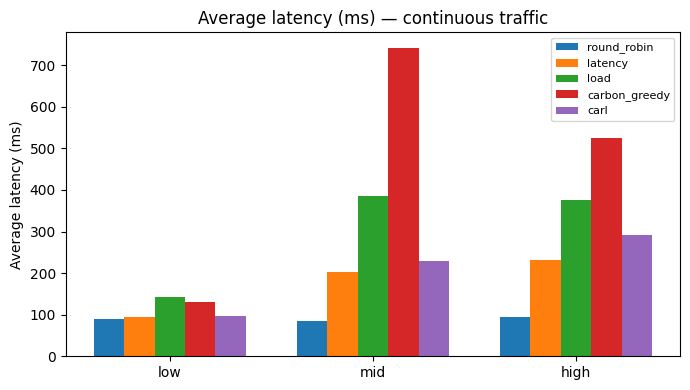

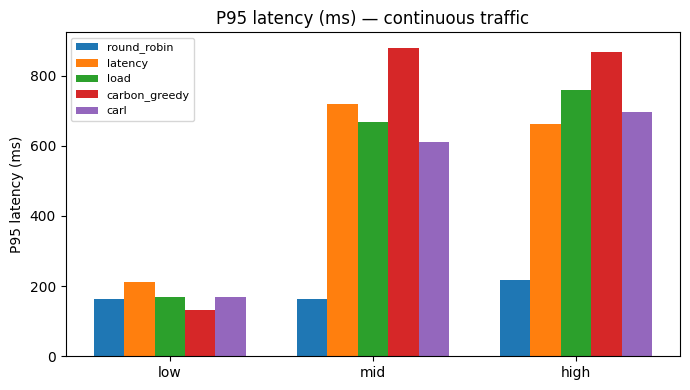

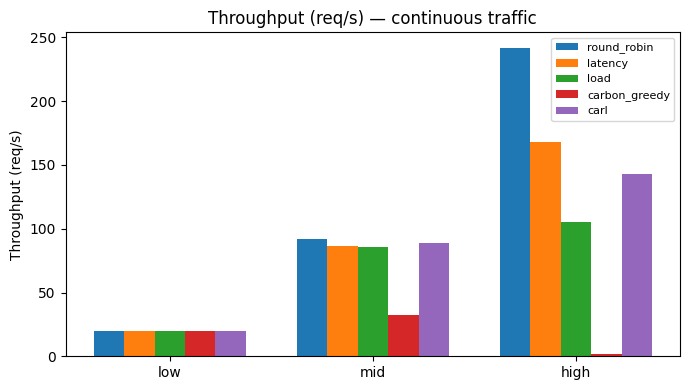

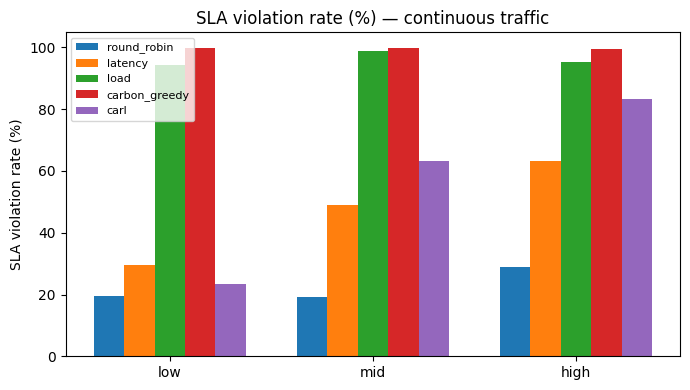

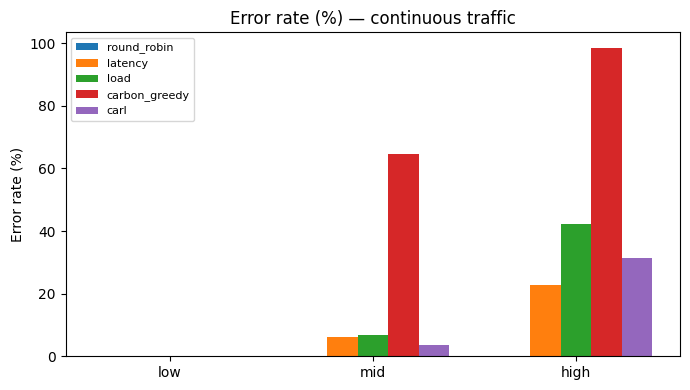

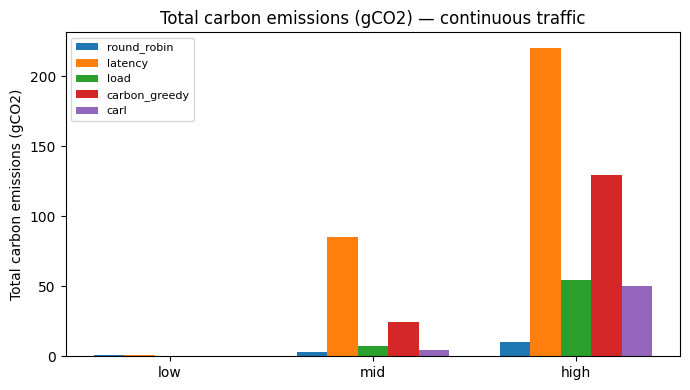

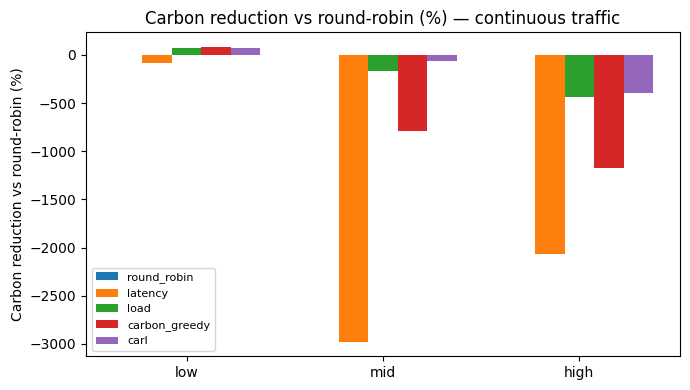

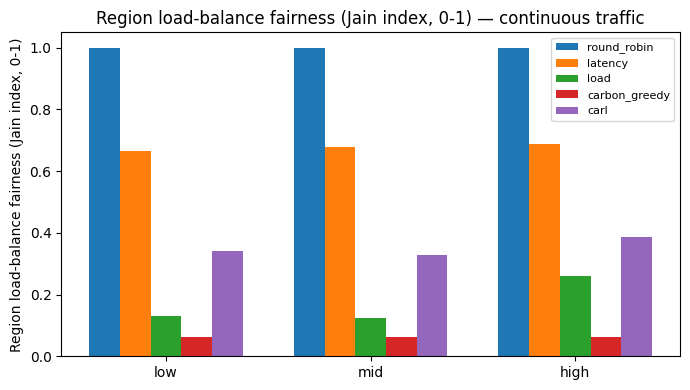

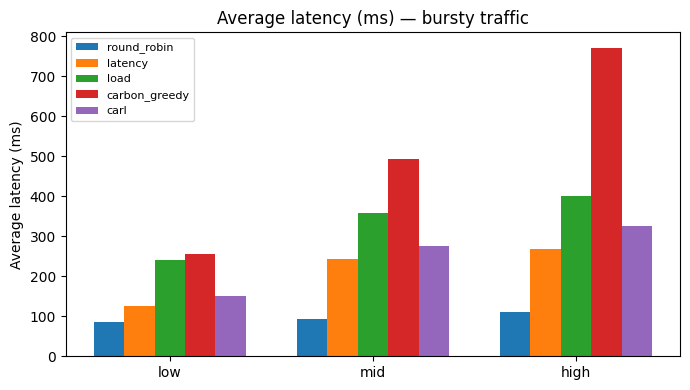

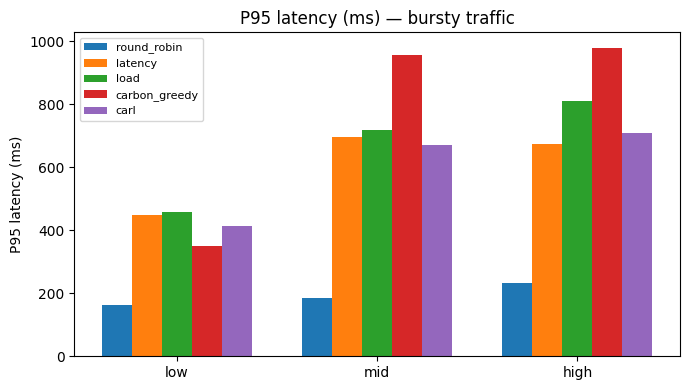

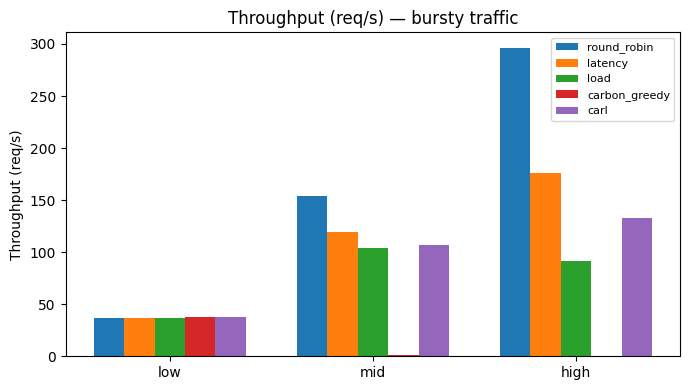

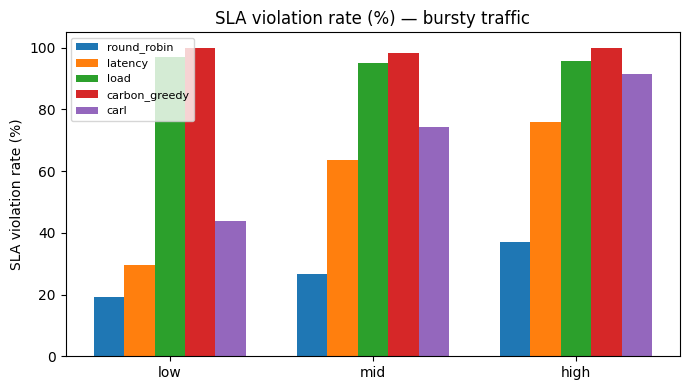

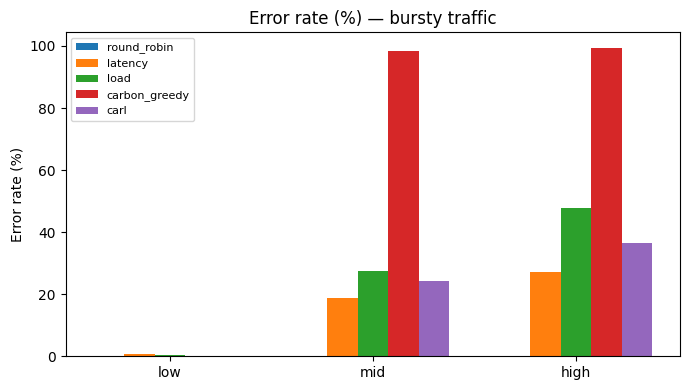

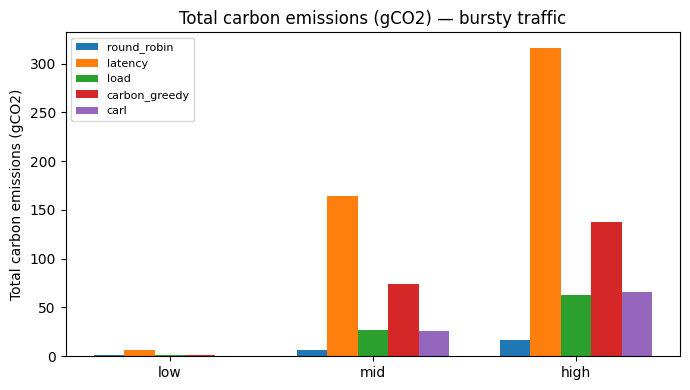

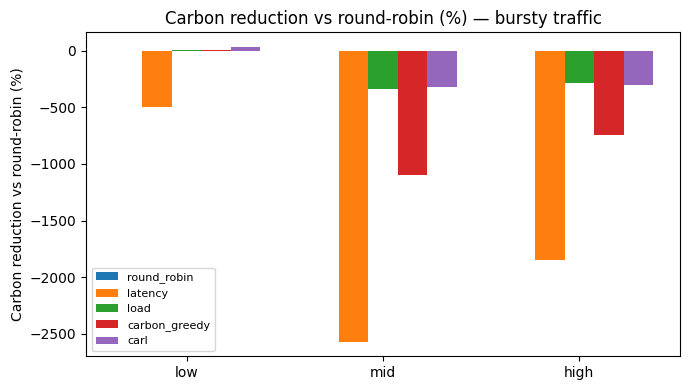

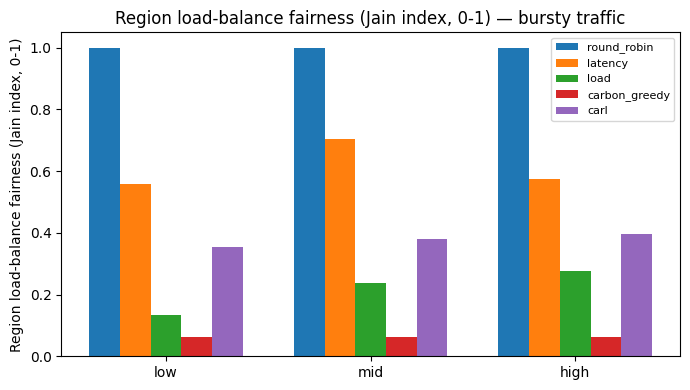

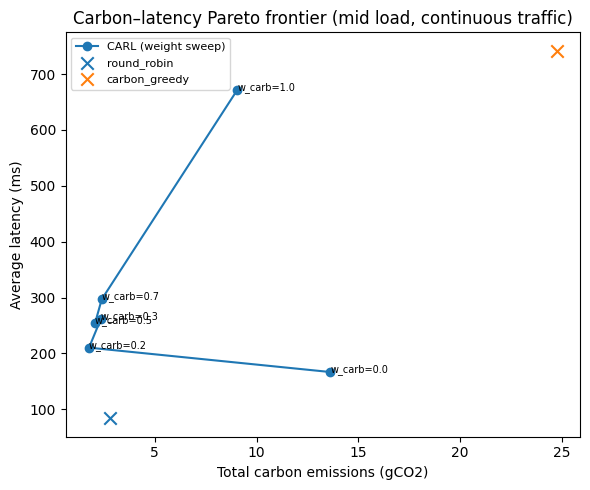

Plots saved in analysis/plots/


In [38]:
# CELL 14
import matplotlib.pyplot as plt
import numpy as np

metrics_to_plot = [
    ("avg_latency_ms", "Average latency (ms)"),
    ("p95_latency_ms", "P95 latency (ms)"),
    ("throughput_rps", "Throughput (req/s)"),
    ("sla_violation_pct", "SLA violation rate (%)"),
    ("error_rate_pct", "Error rate (%)"),
    ("total_carbon_g", "Total carbon emissions (gCO2)"),
    ("carbon_reduction_vs_rr_pct", "Carbon reduction vs round-robin (%)"),
    ("region_fairness_jain", "Region load-balance fairness (Jain index, 0-1)"),
]

for pattern in PATTERNS:
    for metric, ylabel in metrics_to_plot:
        fig, ax = plt.subplots(figsize=(7, 4))
        x = np.arange(len(LEVELS))
        width = 0.15
        for i, mode in enumerate(MODES):
            vals = [summary[(summary.level==l)&(summary.pattern==pattern)&(summary["mode"]==mode)][metric].values[0]
                    if len(summary[(summary.level==l)&(summary.pattern==pattern)&(summary["mode"]==mode)]) else np.nan
                    for l in LEVELS]
            ax.bar(x + i*width, vals, width, label=mode)
        ax.set_xticks(x + width*2)
        ax.set_xticklabels(LEVELS)
        ax.set_ylabel(ylabel)
        ax.set_title(f"{ylabel} — {pattern} traffic")
        ax.legend(fontsize=8)
        plt.tight_layout()
        plt.savefig(f"analysis/plots/{pattern}__{metric}.png", dpi=200)
        plt.show()

# Pareto frontier: carbon vs latency trade-off across CARL weight settings
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(sens_df["total_carbon_g"], sens_df["avg_latency_ms"], "o-", label="CARL (weight sweep)")
for _, row in sens_df.iterrows():
    ax.annotate(f"w_carb={row.w_carb}", (row.total_carbon_g, row.avg_latency_ms), fontsize=7)

ref = summary[(summary.level=="mid") & (summary.pattern=="continuous")]
for mode in ["round_robin", "carbon_greedy"]:
    r = ref[ref["mode"] == mode]
    if len(r):
        ax.scatter(r["total_carbon_g"], r["avg_latency_ms"], marker="x", s=80, label=mode)

ax.set_xlabel("Total carbon emissions (gCO2)")
ax.set_ylabel("Average latency (ms)")
ax.set_title("Carbon–latency Pareto frontier (mid load, continuous traffic)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("analysis/plots/pareto_frontier.png", dpi=200)
plt.show()

print("Plots saved in analysis/plots/")

In [39]:
# CELL 15
import shutil
from google.colab import files

shutil.make_archive("carl_experiment_results", "zip", ".", "analysis")
files.download("carl_experiment_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>